# Treasury rates and SOFR

```
Pull 5Y and 10Y Treasury yields and SOFR from the FRED API (St. Louis Fed),
align them by date, and save a CSV plus plots.

Setup:
    pip install requests pandas matplotlib python-dotenv
    Put your key in the repo root .env as:  FRED_API_KEY=your_key_here
    (the FRED calls themselves live in fred_api.py at the repo root)

Outputs (written to output/ next to this script):
    treasury_sofr.csv           columns: date, UST_5Y, UST_10Y, SOFR (percent)
    treasury_sofr_levels.png    all three series
    treasury_sofr_slope.png     10Y minus 5Y yield spread

Task 1: Treasury rates
- Pull DGS5 and DGS10 (5- and 10-year Treasury yields) and SOFR (the short-term borrowing rate - affects fund's cost of leverage).
- Use FRED API (St. Louis Fed)
- Clean the data: drop missing days, align dates, save to CSV.
- Plot the 5-year and 10-year yields over the last 5–10 years, plus the 10Y − 5Y gap.
```

## Setup
`__file__` doesn't exist in a notebook, so paths are found from the working directory (works whether Jupyter is started in the repo root or in `treasury_rates/`).

In [28]:
SAVE_DATA = False

import sys
from pathlib import Path

# Get access to fred_api.py
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from fred_api import clean_dataset, get_dataset, report_missing

import pandas as pd
from matplotlib import pyplot as plt

## Parameters

In [29]:
# Column name on chart -> FRED series ID
SERIES = {
    "UST_5Y": "DGS5",    # 5-Year Treasury constant-maturity yield (%)
    "UST_10Y": "DGS10",  # 10-Year Treasury constant-maturity yield (%)
    "SOFR": "SOFR",      # Secured Overnight Financing Rate (%)
}

# Date format yyyy-mm-dd
# SOFR only starts on 2018-04-03; the first date of the FRED 5Y and 10Y series (DGS5, DGS10) is 1962-01-02
START_DATE = "2018-04-03"
END_DATE = None  # None = latest available
FFILL = False    # True = forward-fill missing dates (e.g. holidays) instead of leaving blanks

OUTPUT_DIR = ROOT / "treasury_rates" / "output"

## 1. Fetch the three series and align them by date

In [30]:
data = get_dataset(SERIES, START_DATE, END_DATE, FFILL)

## 2. Check coverage and gaps, then clean
Common date range, short gaps filled, no NaNs.

In [31]:
report_missing(data)
if not FFILL:
    data = clean_dataset(data)
else:
    data = clean_dataset(data, 3)

print(f"After cleaning: {len(data)} rows, {data.index.min():%Y-%m-%d} to {data.index.max():%Y-%m-%d}")
data.tail()

2143 rows, 2018-04-03 to 2026-10-27
  UST_5Y: 0 missing observation(s)
  UST_10Y: 0 missing observation(s)
  SOFR: 3 missing observation(s)
    dates: 2021-04-02, 2023-04-07, 2026-04-03
After cleaning: 2140 rows, 2018-04-03 to 2026-10-27


,UST_5Y,UST_10Y,SOFR
date,,,
2026-10-21,4.95,5.13,3.88
2026-10-22,4.78,4.96,3.90
2026-10-23,4.82,5.00,3.92
2026-10-26,4.84,5.00,3.93
2026-10-27,4.82,4.99,3.95


## 3. Save the cleaned CSV

In [32]:
if SAVE_DATA:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    csv_path = OUTPUT_DIR / "t-bill_data.csv"
    data.to_csv(csv_path)
    print(f"Saved {csv_path}")

## 4. Plot the levels and the 10Y-5Y spread

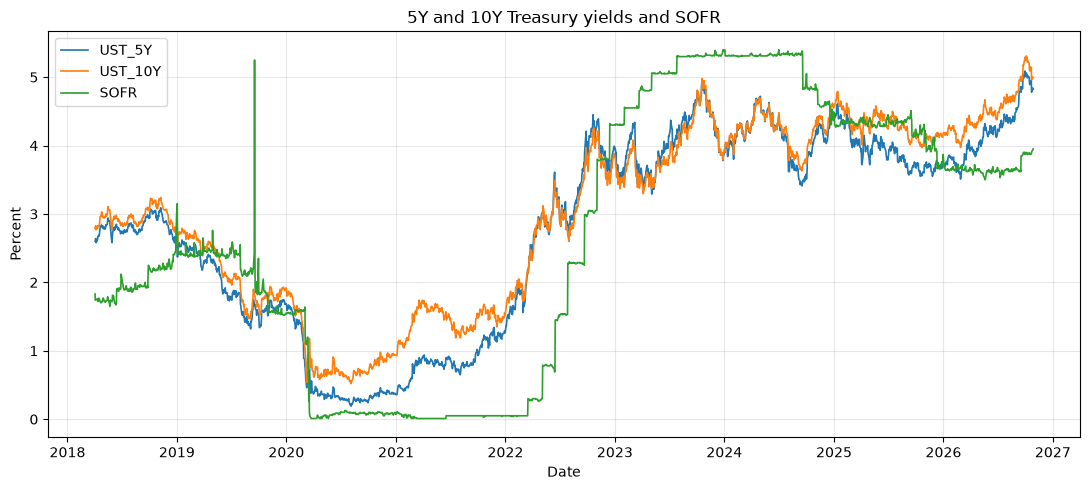

In [33]:
def plot_treasury_yields_and_sofr(data: pd.DataFrame) -> None:
    """Plot all three series on one chart."""
    fig, ax = plt.subplots(figsize=(11, 5))
    for col in data.columns:
        ax.plot(data.index, data[col], linewidth=1.2, label=col)
    ax.set_title("5Y and 10Y Treasury yields and SOFR")
    ax.set_xlabel("Date")
    ax.set_ylabel("Percent")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    
    if SAVE_DATA:
        fig.savefig(OUTPUT_DIR / "T-bill_5y_and_10y_yeilds.png", dpi=150)

    plt.show()
    
plot_treasury_yields_and_sofr(data)

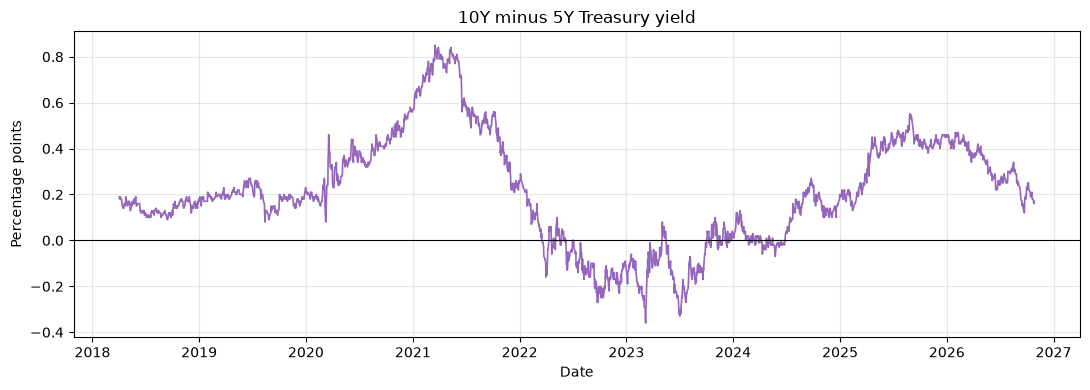

In [34]:
def plot_10y_minus_5y_spread(data: pd.DataFrame) -> None:
    """Plot the 10Y minus 5Y yield spread."""
    slope = data["UST_10Y"] - data["UST_5Y"]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(slope.index, slope, linewidth=1.2, color="tab:purple")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title("10Y minus 5Y Treasury yield")
    ax.set_xlabel("Date")
    ax.set_ylabel("Percentage points")
    ax.grid(alpha=0.3)
    fig.tight_layout()

    if SAVE_DATA:
        fig.savefig(OUTPUT_DIR / "T-bill_10y-5y_spread.png", dpi=150)
        
    plt.show()

plot_10y_minus_5y_spread(data)

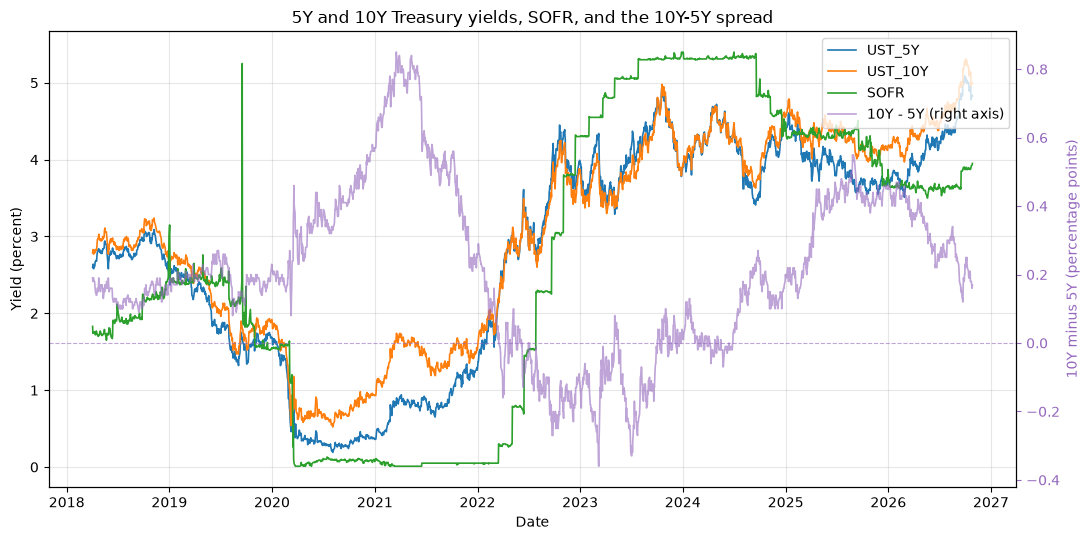

In [35]:
def plot_yields_sofr_and_spread_overlay(data: pd.DataFrame) -> None:
    """Plot the three series (left axis) with the 10Y minus 5Y spread on a right axis."""
    slope = data["UST_10Y"] - data["UST_5Y"]
    fig, ax = plt.subplots(figsize=(11, 5.5))
    for col in data.columns:
        ax.plot(data.index, data[col], linewidth=1.2, label=col)
    ax.set_title("5Y and 10Y Treasury yields, SOFR, and the 10Y-5Y spread")
    ax.set_xlabel("Date")
    ax.set_ylabel("Yield (percent)")
    ax.grid(alpha=0.3)

    # Spread on its own axis so it isn't squashed against the yield levels
    ax2 = ax.twinx()
    ax2.plot(slope.index, slope, linewidth=1.2, color="tab:purple", alpha=0.6,
             label="10Y - 5Y (right axis)")
    ax2.axhline(0, color="tab:purple", linewidth=0.8, linestyle="--", alpha=0.6)
    ax2.set_ylabel("10Y minus 5Y (percentage points)", color="tab:purple")
    ax2.tick_params(axis="y", colors="tab:purple")

    # One legend for both axes
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, loc="upper right")
    fig.tight_layout()

    if SAVE_DATA:
        fig.savefig(OUTPUT_DIR / "T-bill_spread_and_yeild_overlay.png", dpi=150)
    
    plt.show()

plot_yields_sofr_and_spread_overlay(data)